In [1]:
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# We will now scale up to 3D because it has physical meaning unlike 1D
# Assumptions:
# Sigma will be the Identity (3x3) - Homogeneous and Isotropic
# Structured grid
# Add Gaussian noise to fix the inverse crime
# We will introduce sparse electrodes (ill-posed problem)

In [3]:
# numpy casting helper function
def to_numpy(tensor):
    """np.gradient needs a numpy array: pass numpy straight through, otherwise
    detach the torch tensor from the graph and convert."""
    if isinstance(tensor, np.ndarray):
        return tensor
    return tensor.detach().cpu().numpy()

## Collapsed Maxwell Equations

Conductivity-weighted Poisson problem with homogeneous Neumann boundary condition (perfectly insulating boundaries):

$$
\begin{cases}
\nabla \cdot (\sigma \nabla \phi) = -I & \text{in } \Omega \\[4pt]
\sigma \dfrac{\partial \phi}{\partial \mathbf{n}} = \sigma \nabla \phi \cdot \mathbf{n} = 0 & \text{on } \partial\Omega
\end{cases}
$$

The current source density $I(x)$ is interpreted as the volume density of current entering or leaving the extracellular medium at position $x \in \Omega$. A
negative CSD corresponds to current leaving the extracellular medium
(due to the bre transmembrane currents) and is thus conventionally
called a sink. Likewise, current entering the extracellular medium is
called a source (excerpt from the paper below)

**Reference**: <br>
maksymenko2023, <br>
author  = {K. Maksymenko and A. K. Clarke and I. {Mendez Guerra} and S. Deslauriers-Gauthier and D. Farina}, <br>
title   = {A myoelectric digital twin for fast and realistic modelling in deep learning}, <br>
journal = {Nature Communications}, <br>
volume  = {14}, <br>
pages   = {1600}, <br>
year    = {2023}, <br>
doi     = {10.1038/s41467-023-37238-w}

Here $\Omega \ \subseteq \mathbb{R^3}$ because we are in 3D. <br>

In this notebook, for simplicity we shall consider the tissue conductivity tensor $\sigma$ to be constant (homogeneous and isotropic case), so it can be factored out. <br>
The differential equation itself can never be homogeneous as we require $I \neq 0$, where $I$ is the current source density. In the inverse problem, this is the parameter we aim to retrieve given $\phi$ (our data) from the sEMG readings.

Therefore, our equation simplifies to:
$$
\sigma \nabla^2 \phi(x) = -I(x)
$$

where $I \neq 0$, $x \in \mathbb{R}^3, \sigma \in \mathbb{R}^{3 \times 3}$.

For ease we will set $\sigma = I_3 = \begin{pmatrix} 1 & 0 & 0 \\ 0 & 1 & 0 \\ 0 & 0 & 1 \end{pmatrix}$, the $3 \times 3$ identity matrix, which simplifies the tissue conductivity-weighted operator to the ordinary Laplacian (divergence of the gradient) $\nabla^2 \phi = \partial_{xx}\phi + \partial_{yy}\phi + \partial_{zz}\phi$ and we arrive at an even simpler equation:
$$
\nabla^2 \phi(x) = -I(x).
$$


In [4]:
# 3D domain setup

# reproducibility
# inverse problem involves optimisation from an initial guess
torch.manual_seed(42)
np.random.seed(42)

# double precision needed throughout
# float32 causes round-off errors in the gradient when we differentiate for the inverse problem
torch.set_default_dtype(torch.float64)

# 3D domain - [0, L]^3
L = 1.0
N = 65  # number of grid points per axis

# vertex-centred structured grid
t = torch.linspace(0.0, L, N)
h = t[1] - t[0]  # constant grid spacing

X, Y, Z = torch.meshgrid(t, t, t, indexing="ij") # we need this for finite differencing later
x = torch.stack([X, Y, Z], axis=-1)

assert X.shape == Y.shape == Z.shape == (N, N, N)
assert x.shape == (N, N, N, 3)

print(f"Domain [0, {L}]^3 discretised with N = {N} points per axis ({N**3:,} total grid points)")
print(f"Grid spacing h = {h.item():.6f} = L/(N-1) = {L/(N-1):.6f}")
print(f"Coordinate grids X, Y, Z each have shape {tuple(X.shape)}")

# quick grid spacing checks
assert torch.isclose(x[-1, -1, -2][2], torch.tensor(1 - 1/64))
assert torch.isclose(x[-1, -1, -1][2] - x[-1, -1, -2][2], h)

Domain [0, 1.0]^3 discretised with N = 65 points per axis (274,625 total grid points)
Grid spacing h = 0.015625 = L/(N-1) = 0.015625
Coordinate grids X, Y, Z each have shape (65, 65, 65)


Point about notation, $\phi_{i,j,k}$ is shorthand for $\phi(x_{i,j,k})$, where $(i, j, k)$ are the spatial coordinates within the 3D boundary $\Omega \subseteq \mathbb{R^3}$.

Recall in 3D under our assumption, the continuous problem is: <br> $ \nabla^2 \phi(x) = -I(x)$ on $[0, L]^3$, where $x \in \mathbb{R}^3$ <br> subject to homogeneous Neumann boundary conditions $\nabla \phi \cdot \mathbf{n} = 0$ on $\partial\Omega$ (zero normal derivative on all six faces of the cube).

We will discretise the Laplacian $\nabla^2 \phi = \partial_{xx}\phi + \partial_{yy}\phi + \partial_{zz}\phi$ by applying the 3-point second-order central difference scheme along each axis independently. <br> For an interior node $(i, j, k)$:

$$
\nabla^2 \phi_{i,j,k} \approx \frac{1}{h^2}\Big[\big(\phi_{i+1,j,k} - 2\phi_{i,j,k} + \phi_{i-1,j,k}\big) + \big(\phi_{i,j+1,k} - 2\phi_{i,j,k} + \phi_{i,j-1,k}\big) + \big(\phi_{i,j,k+1} - 2\phi_{i,j,k} + \phi_{i,j,k-1}\big)\Big]
$$

Collecting the contributions from all three axes gives the **7-point stencil**: a weight of $-6$ on the centre node and $+1$ on each of its six face-neighbours, all scaled by $1/h^2$. <br> This is the 3D analogue of the 1D stencil, $[1, -2, 1]/h^2$, and it is the set of weights in the $3 \times 3 \times 3$ kernel of the convolutional layer (Neural Physics approach).

We will now implement this below:

In [5]:
# CNN layer carries a classical numerical operator exactly
# create the 3D kernel
kernel = torch.zeros(3, 3, 3, dtype=torch.float64)
kernel[1, 1, 1] = -6.0 # centre node
kernel[0, 1, 1] = kernel[2, 1, 1] = 1.0
kernel[1, 0, 1] = kernel[1, 2, 1] = 1.0
kernel[1, 1, 0] = kernel[1, 1, 2] = 1.0
kernel /= h**2

assert np.isclose(kernel.sum().item(), 0.0)

weight = kernel.view(1, 1, 3, 3, 3) # Conv3d expects a weight tensor of shape (out_channels, in_channel, kernel)

print(f"Kernel has shape {kernel.shape}.")
print(f"Weight has shape {weight.shape}.") # (out_channels=1, in_channels=1, kernel=3)

Kernel has shape torch.Size([3, 3, 3]).
Weight has shape torch.Size([1, 1, 3, 3, 3]).


We need to use reflect padding like the above cell outlines because it obeys the physics of the homogeneous Neumann boundary condition (insulating boundary). Let's consider the low face of one axis (node index $0$ i.e. $\phi[0]$, where the outward normal points in the $-x$ direction). To approximate the normal derivative at the boundary node (index 0), we use a 2nd order central difference scheme centred at $\phi[0]$, which requires a ghost node at index $-1$ ($\phi[-1]$):

$\left.\dfrac{\partial \phi(x)}{\partial x}\right|_{i=0} \approx \dfrac{\phi(x_{1,j,k}) - \phi(x_{-1,j,k})}{2h}$

Now we impose the homogeneous Neumann boundary (zero flux) $\sigma \dfrac{\partial \phi}{\partial \mathbf{n}} \mathbf{n} = 0$, so we set the above expression to $0$:

$\dfrac{\phi(x_{1,j,k}) - \phi(x_{-1,j,k})}{2h} = 0 \implies \phi(x_{1,j,k}) = \phi(x_{-1,j,k})$.

This yields our ghost node value of $\phi(x_{-1,j,k}) = \phi(x_{1,j,k})$, which we implement above. We follow the same method on the high face $\phi(x_{N,j,k}) = \phi(x_{N-2,j,k})$

And we set up normal derivatives similarly at the remaining $4$ faces of our domain (i.e. we do it at both the boundary nodes for each spatial direction $i, j, k$ to give $6$ faces in total).

In [6]:
# the boundary conditions goes on the sides of the kernel
# Computers and Fluids Paper 2026
# Neural physics: Using AI libraries to develop physics-based solvers for incompressible computational fluid dynamics
# Boyang Chen a, Claire E. Heaney b, Christopher C. Pain

In [7]:
def laplacian_kernel(h):
    """
    7-point-stencil weights for sigma*∇² (sigma = 1) at spacing h, shaped as a
    conv3d weight tensor (out=1, in=1, 3, 3, 3). The stencil pattern is the same on
    every level; only the 1/h² scaling changes to avoid hardcoding the resolution of the
    discretisation.
    """
    k = torch.zeros(3, 3, 3)
    k[1, 1, 1] = -6.0                       # centre node
    k[0, 1, 1] = k[2, 1, 1] = 1.0           # ±x face-neighbours
    k[1, 0, 1] = k[1, 2, 1] = 1.0           # ±y face-neighbours
    k[1, 1, 0] = k[1, 1, 2] = 1.0           # ±z face-neighbours
    k /= h ** 2
    return k.view(1, 1, 3, 3, 3)

In [8]:
def laplacian_3D(phi, h):
    """
    Extend Laplacian function from notebook 1D demo to the 3D case.
    3D analogue of the 1D laplacian: applies sigma * ∇²  (sigma = 1) as a fixed-weight
    7-point-stencil conv3d. Reflect padding sets the ghost nodes on all six faces
    (phi[-1]=phi[1], phi[N]=phi[N-2] in each axis) - this approach was also used in the 1D case.
    """
    n = phi.shape[0]
    assert phi.shape == (n, n, n)
    phi_in  = phi.view(1, 1, n, n, n)                              # (batch, channel, D, H, W)
    phi_pad = F.pad(phi_in, (1, 1, 1, 1, 1, 1), mode="reflect")    # pad all 3 spatial axes - mirror about the boundary node
    return F.conv3d(phi_pad, laplacian_kernel(h)).view(n, n, n)



# mode="reflect" the padded values are copies of existing interior values of phi, mirrored across each face
# take a single axis with values phi[0], phi[1], phi[2],..., phi[N-2], phi[N-1]
# after reflect padding by 1 on each side, the row becomes
# phi[1], phi[0], phi[1], phi[2],..., phi[N-2], phi[N-1], phi[N-2]
# ↑ghost--------------------------------------------------↑ghost
# i.e phi[-1] = phi[1], phi[N] = phi[N-2]

Our homogeneous Neumann boundary condition yields yet another result we need to account for. Let us integrate the governing PDE over our domain $\Omega$,

$$
\begin{aligned}
\int_\Omega -I\, dV &= \int_\Omega \nabla \cdot (\sigma \nabla\phi)\, dV && \text{by our collapsed maxwell equation} \\[2mm]
&= \oint_{\partial\Omega} \mathbf{n} \cdot (\sigma \nabla\phi)\, dS && \text{by the Divergence Theorem} \\[2mm]
&= 0 && \text{by our boundary condition} \\[2mm]
\implies \int_\Omega I\, dV &= 0\,.
\end{aligned}
$$

https://en.wikipedia.org/wiki/Divergence_theorem

This means our current source distribution has zero-mean.

The skin-air interface is the insulating boundary - we ignore the connductivity of air (as per the Lucas Mesin 2013 paper referenced in the project plan literature review).

Since there is net zero flux through $\partial\Omega$ (no current density can escape through the boundary), then intuitively the total current density injected must be the same as the amount that's absorbed i.e. the sinks and sources cancel each other out. And we can also see the algebraic justification for this above.

However, the above algebra highlights the solvability condition in the continuos case, but we are working in the discrete scenario. Therefore, to motivate our implementation of this requirement, we need to introduce some background linear algebra.

The orthogonal complement of a subspace $W$ is defined as

$$
W^{\perp} = \{\, v : v \cdot w = 0 \text{ for all } w \in W \,\},
$$

i.e. the set of all vectors which are orthogonal to every vector in $W$.

A matrix $A \in \mathbb{R}^{m \times n}$ has four fundamental subspaces:

1. $\mathrm{Row}(A)$ -- Rowspace of $A$ which is the span of the row vectors of $A$ which is a subspace of $\mathbb{R}^n$.
2. $\mathrm{Col}(A)$ -- The columnspace of $A$ is the span of the column vectors of $A$ which is a subspace of $\mathbb{R}^m$. Note this also the range of $A$ denoted $\mathrm{Range}(A)$.
3. $\mathrm{Ker}(A)$ -- The (right) null space/kernel of $A$ are the vectors that satisfy the equation $Av = 0$.
4. $\mathrm{Ker}(A^{T})$ -- The left null space of $A$ are the vectors that satisfy the equation $A^{T}v = 0$, which is equivalent to $v^{T}A = 0$.

The Fundamental Theorem of Linear Algebra (FTLA) asserts that the left null space of $A$ is the orthogonal complement of the column space of $A$ i.e. $\mathrm{Col}(A) = \mathrm{Ker}(A^{T})^{\perp}$.

For our system $A\phi = b$ to have a solution, we tautologically need $b$ to fall in the span of the column vectors of $A$ because this is how matrix-vector multiplication works. Therefore,

$$
A\phi = b \text{ has a solution} \iff b \in \mathrm{Range}(A) = \mathrm{Col}(A).
$$

And since $\mathrm{Col}(A) = \mathrm{Ker}(A^{T})^{\perp}$ by the FTLA, we have that a solution exists for $A\phi = b$ if and only if $b \in \mathrm{Ker}(A^{T})^{\perp}$ i.e. $b$ lies in the orthogonal complement of the left null space of $A$.

In the discrete case the left null space $\mathrm{Ker}(A^{T})$ is one-dimensional, which is spanned by the trapezoidal weight vector $w$ .i.e. $ \ker(A^{\mathsf{T}}) = \operatorname{span}\{w\} = \{\, c\,w : c \in \mathbb{R} \,\}.$ Therefore, requiring $b$ to be orthogonal to all of $\mathrm{Ker}(A^{T})$ collapses to the single scalar condition $w^{T} b = 0$, which is the discrete solvability condition. The source $b$ must satisfy this condition for $A\phi = b$ to have a solution, which is the discrete analogue of the continuous $\int_{\Omega} I \, dV = 0$ requirement.

We implement this in the impose_net_zero_CSD function below:

In [9]:
# Claude code helped scale up the 1D version of the function to 3D

# 3D rewrite of the zero_mean_condition (the 1D version below used a flat trapezoidal vector w)

def impose_net_zero_CSD(I): # current source density (CSD)
    """
    Project a 3D source field v (shape (N, N, N)) onto the zero-(weighted-)mean
    subspace so that the discrete system A phi = v is solvable.

    Theory (markdown cell above): integrating the PDE over Omega with the
    homogeneous Neumann BC gives the compatibility condition ∫_Ω I dV = 0.
    The discrete analogue is the solvability condition w·v = 0, where w is the
    LEFT null vector of the reflect-padded Laplacian A (i.e. A^T w = 0). On this
    vertex-centred grid that left null vector is exactly the 3D trapezoidal
    quadrature weight field, so w·v is the trapezoidal estimate of ∫_Ω I dV.
    Subtracting the trapezoidal-weighted mean makes any input field admissible.
    """
    n = I.shape[0]

    assert I.shape == (n, n, n) # verify I is a cube

    # 1D trapezoidal weights along a single axis: every node has weight 1, except
    # the two end (boundary) nodes which get weight 1/2 (vertex-centred trap rule).
    w_axis = torch.ones(n)                 # start with weight 1 at every node
    w_axis[0] = w_axis[-1] = 0.5           # halve the two boundary nodes of [0, L]

    # 3D quadrature weight field = outer product of the 1D weights over all 3 axes,
    # so W[i,j,k] = w_axis[i] * w_axis[j] * w_axis[k]. This is the discrete left
    # null vector of A; corners get 1/8, edges 1/4, faces 1/2, interior 1.
    W = torch.einsum("i,j,k->ijk", w_axis, w_axis, w_axis)   # shape (N, N, N)

    # Trapezoidal-weighted mean of v: (W·v)/(W·1). The common h^3 volume factor
    # cancels top and bottom, so this equals (∫v dV)/(∫1 dV) on the grid.
    weighted_mean = (W * I).sum() / W.sum()   # scalar constant to remove

    # Subtract that constant from every node.
    # Then W·(v - weighted_mean) = W·v - weighted_mean*(W·1) = 0,
    # so the projected field satisfies the
    # discrete compatibility condition exactly and A phi = v is now solvable.
    I_net_zero = I - weighted_mean

    # .item() pulls out a Python float so the check works even when I requires grad
    # (e.g. I_hat in the inverse problem); np.isclose on a grad tensor would call
    # .numpy() on it and raise a RuntimeError.
    assert np.isclose((W * I_net_zero).sum().item(), 0) # verify all the sources and sinks cancel out

    return I_net_zero


An important **design choice** we make as a result of the maths:

For any solution $\phi$, we have $\forall c \in \mathbb{R}$, we have $\nabla(\phi + c) = \nabla\phi$. <br> Therefore, the following hold:

$$\nabla \cdot \big(\sigma \nabla(\phi + c)\big) = \nabla \cdot (\sigma \nabla\phi) = -I,$$

$$\mathbf{n} \cdot \big(\sigma \nabla(\phi + c)\big) = \mathbf{n} \cdot (\sigma \nabla\phi) = 0.$$

So $\phi$ is only defined up to an additive constant, this motivates us to impose a further constraint (that we can choose) to ensure uniqueness of a solution.

Since $\phi$ is defined up to a constant, we have that our matrix $A$ (the discretisation of the continous operator $\nabla ^2 \phi$) has a (right) null space that is solved by a non-zero constant vector (i.e. a one-dimensional null space), so to obtain a unique solution, we impose a further constraint on the potential $\phi$. Which we do below:

Note - since $A$ is asymmetric, it's right and left null spaces need not coincide, which we can see in our scenario.

In [10]:
# Design choice:
# Myoelectric paper page 9 - LHS of page - use and reference their explanation
# "obtain a unique solution to the system of Eq. (2), we constrain potentials v to have a zero sum"
# This is how they ensure uniqueness
# this is what we will implement in this demo
# https://www.nature.com/articles/s41467-023-37238-w

def impose_electric_potential_uniqueness(phi):
    """
    Impose uniqueness of phi by constraining the potentials to have 0 sum, as outlined in the linked paper.
    """
    unique_phi = phi - phi.mean() # subtracting the mean yields the unique solution
    # .item() keeps this check valid when phi requires grad (inverse problem) -
    # np.isclose on a grad tensor would try to call .numpy() and raise a RuntimeError.
    assert np.isclose(unique_phi.sum().item(), 0) # verify zero sum condition we want

    return unique_phi

# phi is only defined up to an additive constant due to A·1 = 0 (see the Myoelectric digitial twin paper)
# operator is singular and the source zero-mean;
# impose_phi_uniqueness selects the additive constant in the one-parameter
# family phi + c by constraining the potentials to have zero sum

In [11]:
# make sure the shape and central node of weight didn't get messed up
assert weight.shape == (1, 1, 3, 3, 3)
assert np.isclose(weight[0, 0, 1, 1, 1] *  (h**2), -6.0)

# Jacobi diagonal
# in 3D every row of the 7-point-stencil operator has centre weight -6/h^2 (sigma = 1),
# so D = (-6/h**2) I - inverse of a diagonal matrix is the reciprocal of the diagonal entries
D_inv = 1.0 / weight[0, 0, 1, 1, 1] # centre node of kernel = -6/h^2, so D_inv = -h^2 / 6

sigma = 1.0 # tissue conductivity assumption


# now we initialise I_true (our ground-truth that we manually set)

# 3D analogue of the 1D source field (which used a source/sink pair of Gaussians)
# build I_true from two isotropic 3D Gaussian blobs: a source (+) and a sink (-)
# each blob is exp(-||x - centre||^2 / width^2), centred at distinct points in the cube

width = 0.12

# source blob centred at (0.35, 0.35, 0.35)
g_source = torch.exp(-(((X - 0.35) ** 2 + (Y - 0.35) ** 2 + (Z - 0.35) ** 2) / width ** 2))
# sink blob centred at (0.65, 0.65, 0.65)
g_sink   = torch.exp(-(((X - 0.65) ** 2 + (Y - 0.65) ** 2 + (Z - 0.65) ** 2) / width ** 2))

assert g_source.shape == g_sink.shape == (N, N, N)

I_true = g_source - g_sink # source minus sink

# project onto the zero-mean subspace
I_true = impose_net_zero_CSD(I_true)
assert np.isclose(I_true.sum(), 0.0) # check zero-mean property - every source must be sunk

print(f"I_true has shape {tuple(I_true.shape)}.")
print(f"I_true range: [{I_true.min().item():.4f}, {I_true.max().item():.4f}]")

I_true has shape (65, 65, 65).
I_true range: [-0.9919, 0.9919]


In [12]:
# Here we will add the functions needed to implement a simple 2-grid V-cycle multigrid which I had already made and played around with early in the project
# These were originally implemented for a dense linear solve for a Poission equation
# I used Claude to help implement these functions

Implement our weighted Jacobi update step:

Matrix form (solving $A\phi = I$, with $D = \operatorname{diag}(A)$):

$$
\phi^{(k+1)} = \phi^{(k)} + \omega\, D^{-1}\big(I - A\phi^{(k)}\big).
$$

Laplacian form (here $A = \texttt{laplacian\_3D}$, so $D^{-1} = -h^2/6$):

$$
\phi^{(k+1)} = \phi^{(k)} - \omega\,\frac{h^2}{6}\big(I - \texttt{laplacian\_3D}(\phi^{(k)}, h)\big).
$$

In [13]:
# weighted jacobi - good to ensure convergence within spectral radius - linear algebra theory here!
def jacobi(phi, I, h, omega=2.0 / 3.0, num_iters=1):
    """
    Jacobi update step
    """
    d_inv = -h ** 2 / 6.0
    for _ in range(num_iters):
        residual = I - laplacian_3D(phi, h)
        phi = phi + omega * residual * d_inv
    return phi

**Restriction (3D extension):**

In 3D the full-weighting stencil becomes the tensor (outer) product of the 1D weights $(\tfrac14, \tfrac12, \tfrac14)$ along each axis, giving a $3 \times 3 \times 3$ kernel of 27 weights:

$$
r_{2h}(I,J,K) = \sum_{p,\,q,\,s \,\in\, \{-1,\,0,\,1\}} w_p\, w_q\, w_s \; r_h\big(2I+p,\; 2J+q,\; 2K+s\big),
\qquad w_{-1}=w_{+1}=\tfrac14,\quad w_0=\tfrac12.
$$

By geometry the 27 weights group by how many of the three offsets are $\pm1$:

- centre (coincident node, no $\pm1$): weight $\tfrac18$ — 1 node,
- face neighbours (one $\pm1$): weight $\tfrac{1}{16}$ — 6 nodes,
- edge neighbours (two $\pm1$): weight $\tfrac{1}{32}$ — 12 nodes,
- corner neighbours (three $\pm1$): weight $\tfrac{1}{64}$ — 8 nodes.

These sum to $\tfrac18 + \tfrac{6}{16} + \tfrac{12}{32} + \tfrac{8}{64} = 1$, so constants are preserved (a flat field restricts to the same flat field).

Implementation note: this is a reflect-padded, stride-2 `conv3d`. With `pad=1` the output at coarse index $J$ samples fine indices $(2J-1, 2J, 2J+1)$ per axis; the reflect padding mirrors the missing neighbour at the six faces ($\phi[-1]=\phi[1]$), which is the discrete homogeneous-Neumann condition — the same boundary treatment as `laplacian_3D`. Vertex-centred coarsening requires $N = 2^k+1$ and produces a coarse grid of size $N_c = (N+1)/2$. As in 1D, $R$ is still the adjoint of the trilinear prolongation up to a constant (see the prolongation cell below).

In [14]:
# Used Claude Code to extend the restrict function to the 3d case
def restrict(r_fine):
    """
    Full-weighting restriction (fine -> coarse), 3D.

    Input  r_fine:   (N,   N,   N  ) with N = 2^k + 1
    Output r_coarse: (N_c, N_c, N_c) with N_c = (N + 1) // 2

    The 1D full-weighting stencil (1/4, 1/2, 1/4) becomes its 3x3x3 tensor product
    (a 27-point weighted average summing to 1, so constants are preserved). Implemented
    as a reflect-padded, stride-2 conv3d: with pad=1 the output at coarse index J samples
    fine indices (2J-1, 2J, 2J+1), and the reflect padding mirrors the missing neighbour
    at the faces (phi[-1]=phi[1]) - the discrete homogeneous-Neumann condition, matching
    laplacian_3D.
    """
    n = r_fine.shape[0]
    assert r_fine.shape == (n, n, n)
    assert (n - 1) % 2 == 0, "need N = 2^k + 1 for vertex-centred coarsening"

    w = torch.tensor([0.25, 0.5, 0.25])                       # 1D full-weighting weights
    kernel = torch.einsum("i,j,k->ijk", w, w, w).view(1, 1, 3, 3, 3)

    r_in  = r_fine.view(1, 1, n, n, n)
    r_pad = F.pad(r_in, (1, 1, 1, 1, 1, 1), mode="reflect")   # Neumann mirror at the six faces
    r_coarse = F.conv3d(r_pad, kernel, stride=2)              # stride 2: keep every other node

    n_c = (n + 1) // 2
    return r_coarse.view(n_c, n_c, n_c)

**Prolongation (3D extension):**

The 3D analogue of linear interpolation is trilinear interpolation, which is the tensor product of the 1D linear interpolation along the three axes. With the fine grid sized as $N = 2N_c - 1$ and `align_corners=True`, coarse node $J$ lands exactly on fine node $2J$, and a fine node's value depends on its position relative to the surrounding coarse nodes:

- all three indices even (coincides with a coarse node): exact copy, weight $1$ — 1 coarse node,
- one odd index (midpoint of a coarse edge): average of the $2$ coarse neighbours along that axis, weight $\tfrac12$ each,
- two odd indices (centre of a coarse face): average of the $4$ surrounding coarse nodes, weight $\tfrac14$ each,
- all three odd (centre of a coarse cell): average of the $8$ corner coarse nodes, weight $\tfrac18$ each.

The boundary needs no special Dirichlet handling here: `align_corners=True` pins the coarse endpoints onto the fine endpoints, so boundary fine nodes coincide with boundary coarse nodes and are copied exactly.

Because both operators are tensor products of their 1D counterparts, the 1D variational pairing $P_{1D} = 2\,R_{1D}^\top$ becomes, in 3D,

$$
P = 2^3\, R^\top = 8\,R^\top,
$$

the standard pairing that keeps the Galerkin coarse-grid operator $R A_h P$ symmetric whenever $A_h$ is.

In [15]:
# Used Claude Code to extend the prolong function to the 3d case
def prolong(e_coarse):
    """
    Trilinear-interpolation prolongation (coarse -> fine), 3D.

    Input  e_coarse: (N_c, N_c, N_c)
    Output e_fine:   (N,   N,   N  ) with N = 2 * N_c - 1

    align_corners=True so the coarse endpoints land exactly on the fine endpoints:
    coarse node J maps to fine node 2J (exact copy) and each odd fine node is the
    linear average of its two coarse neighbours.
    """
    n_c = e_coarse.shape[0]
    assert e_coarse.shape == (n_c, n_c, n_c)
    n = 2 * n_c - 1

    e_in   = e_coarse.view(1, 1, n_c, n_c, n_c)
    e_fine = F.interpolate(e_in, size=(n, n, n), mode="trilinear", align_corners=True)
    return e_fine.view(n, n, n)

The recursive (multilevel) V-cycle:

The two-grid idea is applied recursively: the coarse-grid correction equation $A_{2h}\,e_{2h} = r_{2h}$ is itself solved by another V-cycle, descending through successively coarser grids until the grid is small enough to solve cheaply. This generalises the two-grid scheme to any $N = 2^k + 1$.

A single V-cycle call at grid spacing $h$ (size $n$) does the following.

**Base case** ($n \le n_{\text{base}}$, the coarsest grid):

- The operator is singular (homogeneous Neumann), so first enforce the compatibility condition $w \cdot I = 0$ on the RHS (`impose_net_zero_CSD`) — this is *compulsory* for solvability.
- Run `base_iters` Jacobi sweeps; on so few unknowns this is practically an exact solve.
- Pin the free additive constant (`impose_electric_potential_uniqueness`) — a *design choice* for uniqueness — and return.

**Recursive case** ($n > n_{\text{base}}$):

1. **Pre-smoothing** ($\nu_{\text{pre}}$ Jacobi sweeps on grid $h$) — kills high-frequency error so the residual is smooth.
2. **Residual** on grid $h$: $r_h = I - A_h \phi = I - \text{laplacian}(\phi)$.
3. **Restriction**: $r_{2h} = R\, r_h$.
4. **Recursive coarse-grid correction**: enforce compatibility on $r_{2h}$, then solve $A_{2h}\,e_{2h} = r_{2h}$ by a recursive V-cycle call on grid $2h$ with a zero initial guess, and pin the constant of the returned correction $e_{2h}$.
5. **Prolongation**: $e_h = P\, e_{2h}$.
6. **Correction**: $u \leftarrow u + e_h$.
7. **Post-smoothing** ($\nu_{\text{post}}$ Jacobi sweeps on grid $h$) — cleans up high-frequency content introduced by linear interpolation.

The recursion bottoms out at the base case; on the way back up, each level adds its smoothed correction to the finer grid. Setting $\nu_{\text{pre}} = 0$ yields the sawtooth cycle.

In [16]:
# Used Claude Code to extend the 2-grid V-Cycle function to be fully recursive

# Recursive V-cycle
def v_cycle(phi, I, h, omega = (2.0/3.0), nu_pre=2, nu_post=2, base_iters=50, n_base=3):
    """
    Recursive multilevel V-cycle for solving the linear system without the dense
    linear solve (i.e. forming the dense matrix A). Generalises to any N = 2^k + 1.
    """
    n = phi.shape[0]

    # base case - coarsest grids
    # some Jacobi sweeps practically yields an exact solve
    # Singular Neumann operator, so project the RHS for compatibility and project the result to pin the free additive constant
    if n <= n_base:
        rhs = impose_net_zero_CSD(I) # have to do this
        u = jacobi(phi, rhs, h, omega=omega, num_iters=base_iters)
        return impose_electric_potential_uniqueness(u) # design choice

    # 1. pre-smoothing using Jacobi to kill initial high-frequency error
    u = jacobi(phi, I, h, omega=omega, num_iters=nu_pre)

    # 2. compute residual
    r_fine = I - laplacian_3D(u, h) # equivalent to I - A @ phi

    # 3. restrict residual to the coarse grid
    r_coarse = restrict(r_fine)

    # 4. recursive coarse-grid correction: solve A_2h @ e = r_coarse
    h_coarse = 2.0 * h
    r_coarse = impose_net_zero_CSD(r_coarse) # project the RHS to zero-mean for compatability - net current source = 0 (charge conservation)
    e_coarse = torch.zeros_like(r_coarse)
    e_coarse = v_cycle(e_coarse, r_coarse, h_coarse,
                       omega=omega, nu_pre=nu_pre, nu_post=nu_post,
                        base_iters=base_iters, n_base=n_base)
    e_coarse = impose_electric_potential_uniqueness(e_coarse) # project the correction to remove the free constant - phi only defined up to an additive constant

    # 5. prolong correction back to the fine grid
    e_fine = prolong(e_coarse)

    # 6. apply coarse_grid correction
    u = u + e_fine

    # 7. post-smoothing using Jacobi - clean up high frequency errors which appear as a result of the interpolation
    u = jacobi(u, I, h, omega=omega, num_iters=nu_post)

    return u

In [17]:
# our forward function
def forward(I, omega = (2.0/3.0), num_cycles=8, nu_pre=2, nu_post=2, base_iters=50):
    b = impose_net_zero_CSD(I)
    phi = torch.zeros(N, N, N)
    for _ in range(num_cycles):
        phi = v_cycle(phi, b, h,
                        omega=omega, nu_pre=nu_pre, nu_post=nu_post,
                        base_iters=base_iters)
    return impose_electric_potential_uniqueness(phi)

In [18]:
b = impose_net_zero_CSD(I_true)
phi = forward(I_true)
res = torch.linalg.norm(impose_net_zero_CSD(b - laplacian_3D(phi, h)))
print(f"forward residual norm = {res.item():.3e}")

forward residual norm = 1.487e-02


In [19]:
potential_field_obs = forward(I_true).detach() # synthetic electrode measurements - generated from our ground truth parameter I_true

potential_field_obs = to_numpy(potential_field_obs) # cast to numpy array for matplotlib

In [20]:
# Used Claude Code to help with the plotting and creation of the GIF slider

In [21]:
import matplotlib.animation as animation
from IPython.display import HTML

# we use the slider to traverse the depth of the electric potential depth

vmax = np.abs(potential_field_obs).max() # shared symmetric colouur scale

fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(potential_field_obs[:, :, 0].T, origin='lower', extent=[0, L, 0, L],
               cmap='seismic', vmin=-vmax, vmax=vmax) # first frame (k = 0); .T so x is horizontal
fig.colorbar(im, ax=ax, label='φ')
ax.set_xlabel('x'); ax.set_ylabel('y')
title = ax.set_title('')

def update(k):
    im.set_array(potential_field_obs[:, :, k].T) # swap in the k-th z-slice each frame
    title.set_text(f'observed φ   z = {t[k].item():.3f}   (k = {k})')
    return im, title

ani = animation.FuncAnimation(fig, update, frames=N, interval=80) # one frame per z index

plt.close(fig) # prevent the static first frame from also rendering below the animation

HTML(ani.to_jshtml()) # inline, playable in the notebook

In [22]:
# Inverse problem

# we attempt to recover I_true from our observed phi

I_hat = torch.zeros((N, N, N), requires_grad=True) # initialise our initial guess at 0
lr = 0.2
optimiser = torch.optim.Adam([I_hat], lr=lr)

# potential_field_obs was cast to numpy for matplotlib
# bring it back to pytorch tensor
# avoid runtime error
potential_field_obs_t = torch.as_tensor(potential_field_obs)

I_true_norm = torch.linalg.norm(I_true).item() # compute this once outside the loop
loss_history, field_error_history = [], []
max_iters = 200
for i in range(max_iters):
    optimiser.zero_grad() # clear gradients for the next iteration
    potential_field_pred = forward(I_hat) # differentiable forward solve (keep grad - do not detach)
    loss = 0.5 * ((potential_field_pred - potential_field_obs_t) ** 2).sum() # full field data misfit
    loss.backward() # calculate gradients by backpropagating using Jacobi
    optimiser.step() # Adam update of I_hat (update our parameter)

    loss_history.append(loss.item())

    field_error = (torch.linalg.norm(I_hat.detach() - I_true)
                   / I_true_norm).item()
    field_error_history.append(field_error)
    if i % 1 == 0:
        print(f" step {i:3d}: data loss = {loss.item():.2e}   rel field err = {field_error_history[-1]:.3e}")

 step   0: data loss = 6.65e-01   rel field err = 2.454e+00
 step   1: data loss = 3.02e+01   rel field err = 1.236e+00
 step   2: data loss = 2.19e+00   rel field err = 1.479e+00
 step   3: data loss = 6.67e+00   rel field err = 1.957e+00
 step   4: data loss = 1.68e+01   rel field err = 1.729e+00
 step   5: data loss = 1.10e+01   rel field err = 1.261e+00
 step   6: data loss = 1.91e+00   rel field err = 1.165e+00
 step   7: data loss = 7.27e-01   rel field err = 1.443e+00
 step   8: data loss = 6.00e+00   rel field err = 1.549e+00
 step   9: data loss = 8.78e+00   rel field err = 1.360e+00
 step  10: data loss = 5.86e+00   rel field err = 1.045e+00
 step  11: data loss = 1.41e+00   rel field err = 9.241e-01
 step  12: data loss = 1.17e-01   rel field err = 1.094e+00
 step  13: data loss = 2.38e+00   rel field err = 1.250e+00
 step  14: data loss = 4.67e+00   rel field err = 1.227e+00
 step  15: data loss = 4.19e+00   rel field err = 1.073e+00
 step  16: data loss = 1.77e+00   rel fi

In [23]:
# from google.colab import drive

# # Mount Drive (skip if already mounted this session)
# drive.mount('/content/drive')

# # Detach from the autograd graph and move to CPU, then convert to numpy
# I_hat_np = I_hat.detach().cpu().numpy()

# # Save to your Drive (.npy preserves the (N, N, N) shape and dtype)
# save_path = '/content/drive/MyDrive/I_hat.npy'
# np.save(save_path, I_hat_np)

# print(f"Saved array of shape {I_hat_np.shape}, dtype {I_hat_np.dtype} to {save_path}")

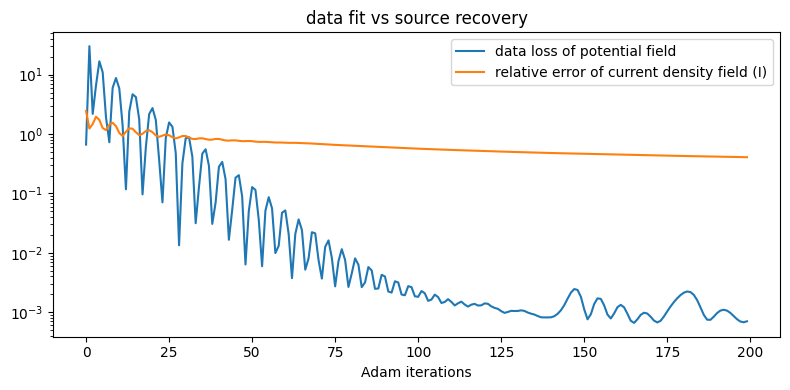

In [24]:
# convergence plot
fig, ax = plt.subplots(figsize=(8, 4))

ax.semilogy(loss_history, label='data loss of potential field') # phi_pred vs phi_obs mismatch
ax.semilogy(field_error_history, label='relative error of current density field (I)') # I_hat vs I_true mismatch
ax.legend()
ax.set_xlabel('Adam iterations')
ax.set_title('data fit vs source recovery')

plt.tight_layout()
plt.show();

In [25]:
# the current source density I is a scalar field, not a vector field
# so can't plot vector field here
# I is one number per point - the volume density of current entering (+) or leaving (-) the medium at (x,y,z) - so has no direction
# plot idea:
# obtain phi from the forward solve using our I_true (we create our realistic synthetic data)
# we then use that with I_true to plot current density J as a 3D vector field
# so after doing repeated iterations of the inverse problem, when we obtain an improved I_hat
# we then use that with our phi (data) to plot our retrieved vector field
# we can then contrast with our true vector field to visualise the delta

Ohm's law in a volume conductor yields current density $J = -\sigma \nabla \phi$, where $J$ is the current density, which is a vector field.

So when we take the divergence of both sides of the above equation, $\nabla \cdot J = \nabla \cdot (-\sigma \nabla \phi)$.

We arrive at our collapsed Maxwell equation where $\nabla \cdot J = I$.

$I(x)$ is the net current produced **per** unit volume, at a point $x$ in our domain $\Omega$. <br> So, as we can see $I$ is a scalar field.

Since, $\nabla J = I$ and $I > 0$ indicates a current source, we have that $J$ points outwards. Naturally, the opposite of this also holds and we will use this orientation when plotting our vector fields below.

In [26]:
# https://en.wikipedia.org/wiki/Current_density

In [27]:
# Use Claude Code to help implement the 3D vector field plots

In [28]:
# helper function to calculate the current density J
def current_density(phi):
    """J = -sigma * grad(phi), via 2nd-order central differences with grid spacing h."""
    dphi_dx, dphi_dy, dphi_dz = np.gradient(phi, float(h), edge_order=2)
    return -sigma * dphi_dx, -sigma * dphi_dy, -sigma * dphi_dz

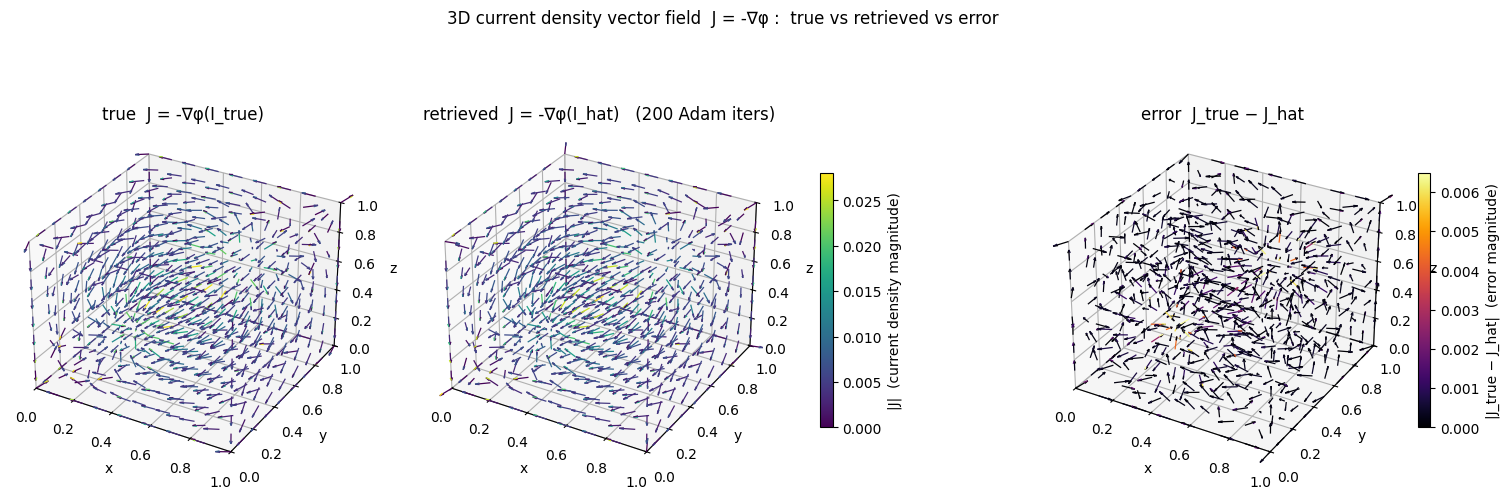

In [29]:
# 3D vector field visualisation
from mpl_toolkits.mplot3d import Axes3D

# Build our current density J vector fields in the following manner:
# true field      : phi_true = potential_field_obs = forward(I_true)
# retrieved field : phi_hat  = forward(I_hat)
# error field     : J_true - J_hat


# cast the forward solves of the true and recovered CSD to numpy (if not already)
phi_true = to_numpy(potential_field_obs)
phi_hat  = to_numpy(forward(I_hat))

U_true, V_true, W_true = current_density(phi_true)
U_hat,  V_hat,  W_hat   = current_density(phi_hat)

# error (delta) vector field, component-wise:  J_true - J_hat
U_err, V_err, W_err = U_true - U_hat, V_true - V_hat, W_true - W_hat




# subsample for a readable vector field
stride = 8 # tune for arrow density (every 8th node per axis)
sub = (slice(None, None, stride),) * 3
Xs, Ys, Zs = X.numpy()[sub], Y.numpy()[sub], Z.numpy()[sub]

def _mag(U, V, W):
    return np.sqrt(U[sub] ** 2 + V[sub] ** 2 + W[sub] ** 2)

# arrow colour scales: panels 1 & 2 share one |J| scale; the error panel gets its own
jmax = max(_mag(U_true, V_true, W_true).max(), _mag(U_hat, V_hat, W_hat).max())
emax = _mag(U_err, V_err, W_err).max()
jnorm = plt.Normalize(0.0, jmax)
enorm = plt.Normalize(0.0, emax)
jcmap, ecmap = plt.cm.viridis, plt.cm.inferno

def plot_current_field(ax, U, V, W, title, vec_norm, vec_cmap):
    Us, Vs, Ws = U[sub], V[sub], W[sub]
    mag = np.sqrt(Us ** 2 + Vs ** 2 + Ws ** 2)

    # colour each arrow by its magnitude. matplotlib's 3D quiver renders every arrow
    # as 1 shaft + 2 head lines, so the colour list must be ordered
    # [shaft_0..shaft_n, head_0..head_n (x2)] - hence the concatenate/repeat below.
    c = vec_norm(mag.ravel())
    arrow_colours = vec_cmap(np.concatenate([c, np.repeat(c, 2)]))
    ax.quiver(Xs, Ys, Zs, Us, Vs, Ws, colors=arrow_colours,
              length=0.07, normalize=True, linewidth=0.9)  # unit-length arrows: direction from shape, magnitude from colour

    ax.set_title(title)
    ax.set_xlabel('x'); ax.set_ylabel('y'); ax.set_zlabel('z')
    ax.set_xlim(0, L); ax.set_ylim(0, L); ax.set_zlim(0, L)

fig = plt.figure(figsize=(19, 6))
ax1 = fig.add_subplot(1, 3, 1, projection='3d')
ax2 = fig.add_subplot(1, 3, 2, projection='3d')
ax3 = fig.add_subplot(1, 3, 3, projection='3d')

plot_current_field(ax1, U_true, V_true, W_true,
                   'true  J = -∇φ(I_true)', jnorm, jcmap)
plot_current_field(ax2, U_hat, V_hat, W_hat,
                   f'retrieved  J = -∇φ(I_hat)   ({max_iters} Adam iters)', jnorm, jcmap)
plot_current_field(ax3, U_err, V_err, W_err,
                   'error  J_true − J_hat', enorm, ecmap)

# colourbar for the true/retrieved arrow magnitude |J| (shared by panels 1 & 2)
sm = plt.cm.ScalarMappable(norm=jnorm, cmap=jcmap); sm.set_array([])
fig.colorbar(sm, ax=[ax1, ax2], label='|J|  (current density magnitude)', shrink=0.55)
# separate colourbar for the error-field magnitude |J_true − J_hat|
sm_err = plt.cm.ScalarMappable(norm=enorm, cmap=ecmap); sm_err.set_array([])
fig.colorbar(sm_err, ax=ax3, label='|J_true − J_hat|  (error magnitude)', shrink=0.55)

fig.suptitle('3D current density vector field  J = -∇φ :  true vs retrieved vs error')
plt.show();

In [30]:
# Used Claude to brainstorm ideas for different norms to compare vector fields
# Used Claude to learn about the H(div) norm and it's appropriateness
# Used Claude to help implement the H(div) norm

Here we will use H(div) norm to assess how good our reconstructed vector field with respect to the ground truth. This norm penalises both the flow mismatch and the source/sink mismatch ($I_{\text{true}}$ − $I_{\text{hat}}$):

$$
\lVert \mathbf{J}\rVert_{H(\text{div})}^2 = \lVert \mathbf{J}\rVert_{L^2}^2 + \lVert \nabla\cdot\mathbf{J}\rVert_{L^2}^2 = \lVert \mathbf{J}\rVert_{L^2}^2 + \lVert I\rVert_{L^2}^2.
$$

In [31]:
# need academic source/ref for the H(div) norm??

In [32]:
# important note
# compute the ∇·J term with the same finite-difference stencil the solver uses
# (the 7-point Laplacian acting on phi),
# so the discrete divergence is consistent with the discrete operator
# otherwise the two halves of the H(div) norm are discretised inconsistently and the number is harder to interpret

In [33]:
# L2 term:  the flow mismatch (orientation and magnitude of current)
# div term: the source/sink mismatch

# div J uses the same 7-point Laplacian the solver uses (laplacian_3D)
# may need to change this when we attempt to use a different resolutions in the forward and inverse solves
# this is a problem for later

# trapezoidal volume-quadrature weight field (same construction as impose_net_zero_CSD)
w_axis = torch.ones(N); w_axis[0] = w_axis[-1] = 0.5
W_quad = to_numpy(torch.einsum("i,j,k->ijk", w_axis, w_axis, w_axis))   # (N, N, N)

# divergence of J via the solver's stencil:  div J = -sigma * lap(phi)  (= discrete I, up to sign)
divJ_true = to_numpy(-sigma * laplacian_3D(torch.as_tensor(phi_true), h))
divJ_hat  = to_numpy(-sigma * laplacian_3D(torch.as_tensor(phi_hat), h))

def L2_sq(*components):
    """Squared L2 norm  ∫_Ω |field|^2 dV  via trapezoidal quadrature (h^3 dropped - cancels in the ratio)."""
    return (W_quad * sum(c ** 2 for c in components)).sum()

# the two halves of the H(div) norm, for the true field and for the error field
L2_J_err   = L2_sq(U_true - U_hat, V_true - V_hat, W_true - W_hat)  # flow error
div_err_sq = L2_sq(divJ_true - divJ_hat)                            # source/sink error
L2_J_true  = L2_sq(U_true, V_true, W_true)
div_true   = L2_sq(divJ_true)

# relative errors (dimensionless - the h^3 factor cancels out)
rel_L2   = np.sqrt(L2_J_err / L2_J_true)                            # flow only
rel_div  = np.sqrt(div_err_sq / div_true)                           # sources/sinks only
rel_Hdiv = np.sqrt((L2_J_err + div_err_sq) / (L2_J_true + div_true))# combined H(div)

print(f"relative errors of the recovered current density  J_hat  ({max_iters} Adam iters)")
print(f"  L2 of J        (flow mismatch)        : {rel_L2:.3e}")
print(f"  L2 of div J=I  (source/sink mismatch) : {rel_div:.3e}")
print(f"  H(div)         (combined)             : {rel_Hdiv:.3e}")

relative errors of the recovered current density  J_hat  (200 Adam iters)
  L2 of J        (flow mismatch)        : 1.143e-01
  L2 of div J=I  (source/sink mismatch) : 4.029e-01
  H(div)         (combined)             : 4.005e-01
